### Dylan Renard
### Applied Machine Learning JHU
### Homework 12
### Professor Alhassan
### April 20th, 2026

## HW Assignment 12: Applied Machine Learning @JHU

#### Credit card fraud costs about 1% of their revenue to the banks, an amount which customers (us) eventually pay. Let's find those anomalies which might reveal a fraud. Download the popular credit card dataset from kaggle.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

#### Q1: Explore the dataset, list the number fo rows and columns, check sanity, and examine the features (e.g. with histograms or plots).

Shape: (284807, 31)
Columns: Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

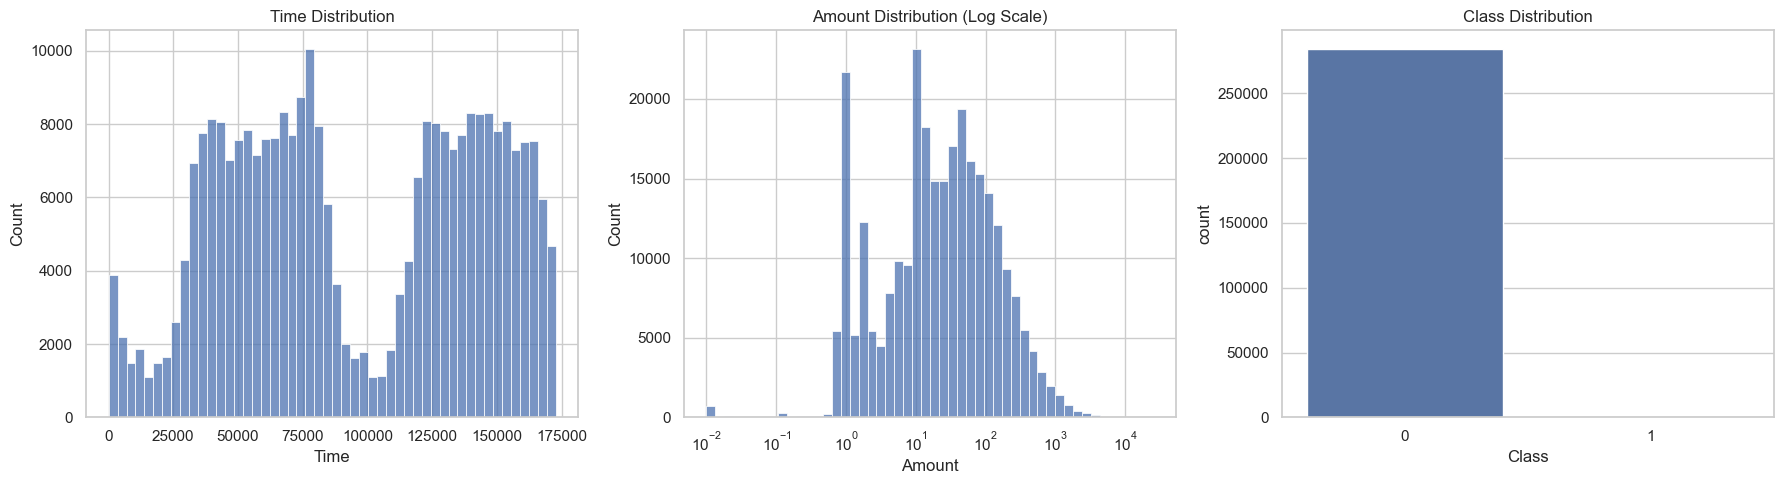

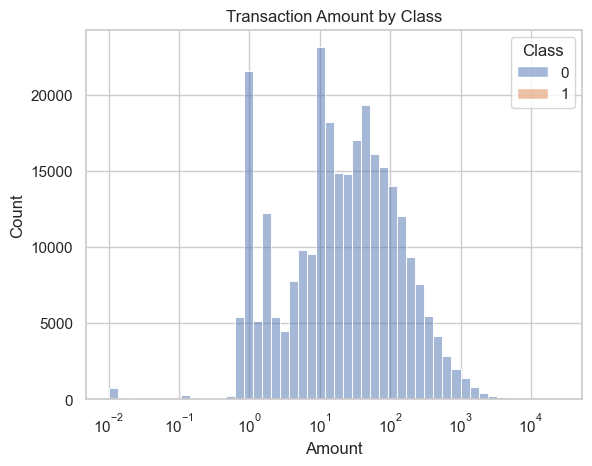

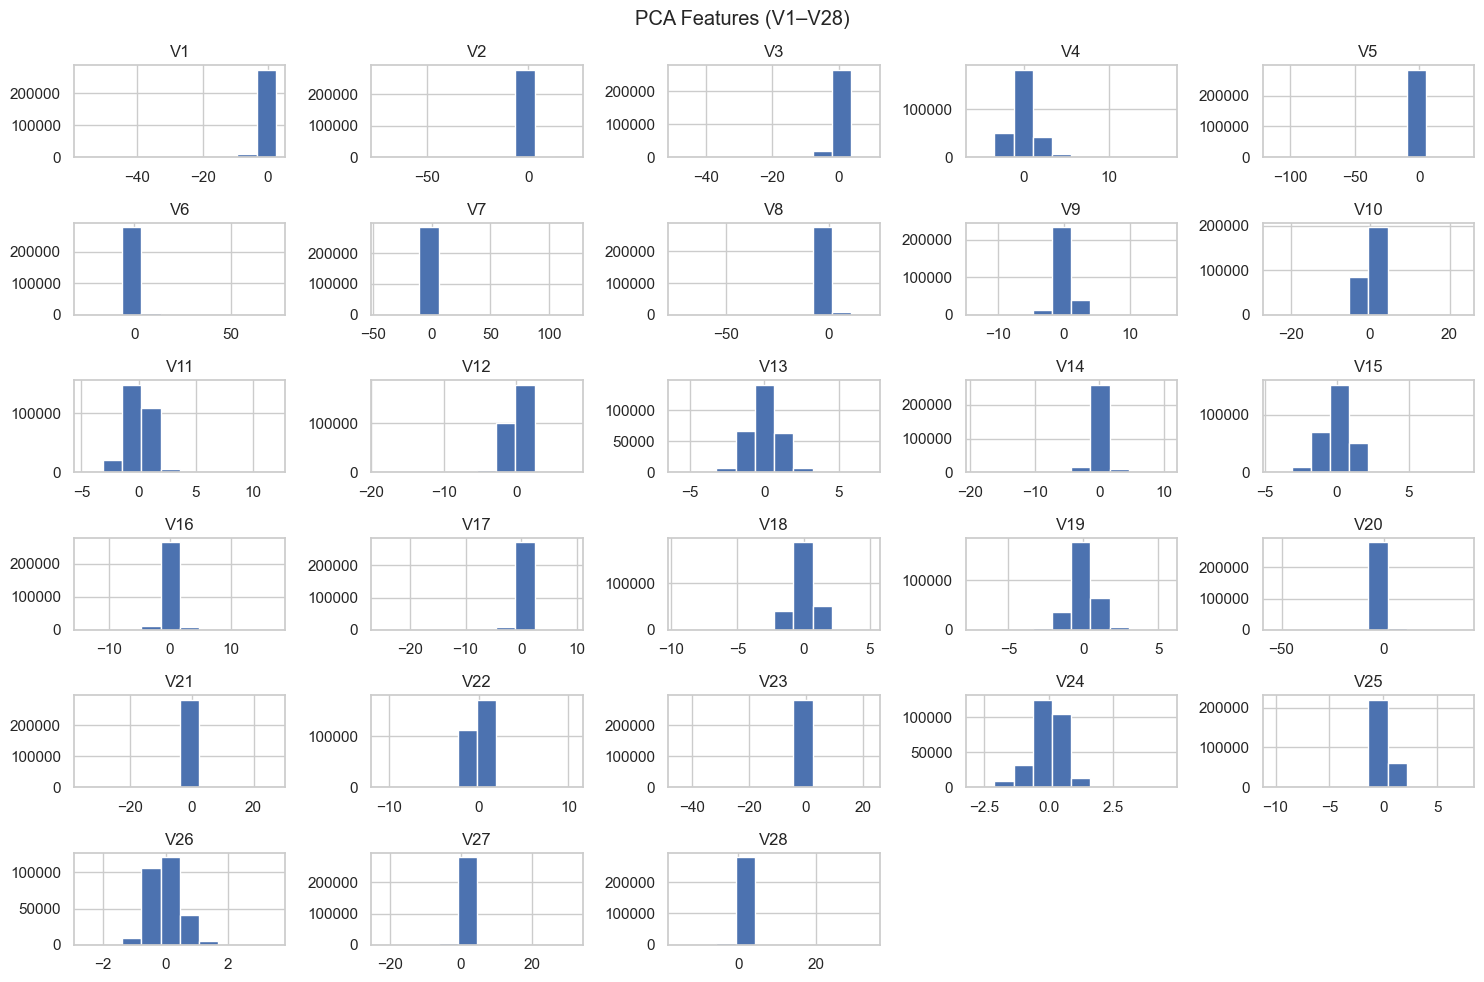

In [4]:
# Basic exploration
print("Shape:", df.shape)
print("Columns:", df.columns)

display(df.head())
df.info()

print("\nMissing values:\n", df.isnull().sum())
print("\nSummary statistics:\n", df.describe())

# Set plotting style
sns.set(style="whitegrid")

# Key feature plots (clean + informative)
fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(df['Time'], bins=50, ax=axes[0])
axes[0].set_title("Time Distribution")

sns.histplot(df['Amount'], bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Amount Distribution (Log Scale)")

sns.countplot(x='Class', data=df, ax=axes[2])
axes[2].set_title("Class Distribution")

plt.tight_layout()
plt.show()

# Amount vs Class (NO KDE → stable)
sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=True
)
plt.title("Transaction Amount by Class")
plt.show()

# PCA features grouped (not overwhelming)
pca_cols = [col for col in df.columns if col.startswith('V')]

df[pca_cols].hist(figsize=(15,10))
plt.suptitle("PCA Features (V1–V28)")
plt.tight_layout()
plt.show()

#### Q1 Interpretation: 
The dataset contains 284,807 rows and 31 columns, consisting of 30 numerical features and one target variable (Class) indicating whether a transaction is fraudulent. A preliminary sanity check confirmed that there are no missing values, and all features are numeric (float64 for predictors and int64 for the target), making the dataset clean and ready for analysis without additional preprocessing for missing data.

The majority of the features (V1–V28) are the result of a principal component analysis (PCA) transformation applied to the original dataset. These features are centered around zero and exhibit varying spreads, as observed in the histograms. While this transformation ensures normalization and reduces multicollinearity, it also limits interpretability, as the original meaning of the variables is not directly accessible.

Exploratory analysis using histograms revealed several important patterns. The transaction amount feature is highly right-skewed, with most transactions occurring at low values and a small number of very large transactions forming a long tail. A logarithmic transformation helps stabilize this distribution but does not fully separate fraudulent from non-fraudulent transactions, indicating that amount alone is not a strong predictor.

The time feature shows a non-uniform distribution across the dataset, suggesting temporal variation in transaction frequency. This may reflect real-world behavioral cycles and indicates potential value in temporal feature engineering.

A critical finding from the dataset exploration is the extreme class imbalance. Fraudulent transactions represent only about 0.17% of the data, while the vast majority are non-fraudulent. This imbalance was confirmed through class distribution plots and has major implications for model development, as standard accuracy metrics would be misleading.

Overall, the dataset is clean, numerically well-structured, and suitable for machine learning. However, the exploratory analysis highlights key challenges, including severe class imbalance, skewed feature distributions, and limited interpretability of PCA-derived features. These factors must be addressed in subsequent modeling steps to build an effective fraud detection system.

#### Q2: Check the class balance, choose an evaluation metric, and justify the choice.

Based on the exploratory analysis in Q1, the dataset is severely imbalanced, with only 492 fraudulent transactions out of 284,807 total observations (approximately 0.17%), while the remaining transactions are non-fraudulent. This imbalance was also evident in the class distribution plots, where fraudulent cases were barely visible compared to the overwhelming majority class. Additionally, the analysis showed that features such as transaction amount are highly skewed and exhibit significant overlap between classes, indicating that fraud detection cannot rely on simple thresholds or single features but instead requires careful evaluation of model performance.

Given this imbalance, accuracy is not an appropriate evaluation metric, as a model predicting only the majority class would still achieve over 99% accuracy while failing to detect any fraudulent transactions. In line with the concepts covered in Module 12, evaluation metrics that better reflect performance on the minority class are required. Precision and recall are more suitable in this context, as they measure the correctness of fraud predictions and the ability to detect actual fraud, respectively. Since missing fraudulent transactions is particularly costly, recall is especially important; however, relying solely on recall may lead to excessive false positives. Therefore, the F1-score is chosen as the primary evaluation metric, as it balances precision and recall and provides a more meaningful assessment of model performance on this highly imbalanced dataset.

#### Q3: Check if you need normalization or standardization, and justify. Complete pre-processing.
Based on the observations from Q1, additional normalization or standardization is not strictly required for the majority of the features, as the variables V1–V28 have already been transformed using PCA and are centered around zero with comparable scales. This indicates that these features have effectively been standardized during preprocessing and are suitable for most machine learning algorithms without further scaling.

However, the Amount feature is highly skewed and exists on a different scale compared to the PCA components, as seen in the distribution plots. To address this, a logarithmic transformation (e.g., log1p) is applied to reduce skewness and bring the feature closer to a normal distribution. This improves model stability and ensures that extreme values do not disproportionately influence the learning process. The Time feature, while not requiring standardization, may not directly contribute meaningful predictive information in its raw form and could benefit from feature engineering, though it is retained as-is for this analysis.

As part of preprocessing, the dataset is split into training and testing sets using stratified sampling to preserve the original class imbalance. Additionally, due to the severe imbalance identified in Q1, a resampling technique such as SMOTE (Synthetic Minority Oversampling Technique) is applied to the training data after baseline metrics are collected to balance the classes and improve the model’s ability to learn patterns associated with fraudulent transactions.

Overall, preprocessing includes applying a log transformation to the Amount feature, performing a stratified train-test split, and addressing class imbalance through resampling, while leaving the PCA-transformed features unchanged due to their already standardized nature.

In [5]:
# ! pip install imblearn
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# -----------------------------
# Baseline preprocessing
# -----------------------------
# V1–V28 are already PCA-transformed / standardized
# Amount is highly skewed, so apply log transform
df["Amount_log"] = np.log1p(df["Amount"])

# Drop original Amount after transformation
df_baseline = df.drop(columns=["Amount"])

# -----------------------------
# Separate features and target
# -----------------------------
X = df_baseline.drop(columns=["Class"])
y = df_baseline["Class"]

# -----------------------------
# 50-50 stratified train-test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    stratify=y,
    random_state=42
)

print("Baseline training set shape:", X_train.shape)
print("Baseline test set shape:", X_test.shape)

print("\nBaseline class distribution in training set:")
print(y_train.value_counts())

print("\nBaseline class distribution in test set:")
print(y_test.value_counts())

# -----------------------------
# SMOTE version (training data only)
# -----------------------------
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nSMOTE training set shape:", X_train_smote.shape)
print("\nClass distribution in SMOTE training set:")
print(pd.Series(y_train_smote).value_counts())

# -----------------------------
# Optional: package datasets clearly
# -----------------------------
baseline_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test
}

smote_data = {
    "X_train": X_train_smote,
    "X_test": X_test,   # test set remains untouched
    "y_train": y_train_smote,
    "y_test": y_test
}



Baseline training set shape: (142403, 30)
Baseline test set shape: (142404, 30)

Baseline class distribution in training set:
Class
0    142157
1       246
Name: count, dtype: int64

Baseline class distribution in test set:
Class
0    142158
1       246
Name: count, dtype: int64

SMOTE training set shape: (284314, 30)

Class distribution in SMOTE training set:
Class
0    142157
1    142157
Name: count, dtype: int64


#### Q4: Split the dataset 50-50 for training and testing. Then, without any tree pruning or regularization, run classifiers of the following types (reporting each one's classification performance):
* SVC
* DecisionTreeClassifier
* MLPClassifier
* RandomForest

In [6]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# --------------------------------------------------
# Q4: Baseline models on imbalanced data (no SMOTE)
# --------------------------------------------------
# Assumes you already created:
# X_train, X_test, y_train, y_test
# from the 50-50 stratified split in Q3

models = {
    "SVC": SVC(kernel="linear"),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
    "MLPClassifier": MLPClassifier(max_iter=200, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42, n_jobs=-1)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*20} {name} {'='*20}")
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, digits=4)
    
    results[name] = {
        "confusion_matrix": cm,
        "classification_report": report
    }
    
    print("Confusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(report)


==================== SVC ====================
Confusion Matrix:
[[142122     36]
 [   181     65]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9987    0.9997    0.9992    142158
           1     0.6436    0.2642    0.3746       246

    accuracy                         0.9985    142404
   macro avg     0.8211    0.6320    0.6869    142404
weighted avg     0.9981    0.9985    0.9982    142404


==================== DecisionTreeClassifier ====================
Confusion Matrix:
[[142093     65]
 [    60    186]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9995    0.9996    142158
           1     0.7410    0.7561    0.7485       246

    accuracy                         0.9991    142404
   macro avg     0.8703    0.8778    0.8740    142404
weighted avg     0.9991    0.9991    0.9991    142404


==================== MLPClassifier ====================
Confusion Matrix:
[[14

#### Q4 Interpretation of results: 
The baseline models demonstrate varying levels of performance on the imbalanced dataset. While overall accuracy is high across all models due to the dominance of the majority class, performance on the minority class differs significantly. The SVC model performs poorly in detecting fraudulent transactions, achieving a recall of only 0.26, indicating that most fraud cases are missed. In contrast, the MLP classifier improves recall to approximately 0.70, though at the cost of lower precision, resulting in more false positives.

The Decision Tree classifier provides a better balance between precision and recall, achieving an F1-score of approximately 0.75 for the minority class. The Random Forest model performs the best overall, with high precision (0.97) and strong recall (0.74), resulting in the highest F1-score among the models. This suggests that ensemble tree-based methods are more effective at capturing patterns associated with fraudulent transactions, even without explicit handling of class imbalance.

These results highlight that while accuracy alone is misleading, models such as Random Forest can still perform well on imbalanced data. However, performance varies across model types, and simpler models like SVC struggle significantly, reinforcing the need for careful model selection and further techniques such as resampling or regularization to improve minority class detection.

#### Q5: Now use tree pruning and/or regularization to run classifiers of the following types: 
* SVC
* DecisionTreeClassifier
* MLPClassifier
(Hint: you might use GridSearchCV to optimize regularization parameters or simply run a few pilot tests). Report each one's classification performance. Make sure to use the same subsets as above to train and test.

#### Q5 Parameter justification and design considerations:
The parameter ranges in Q5 were selected as small pilot tests to evaluate the impact of regularization and model complexity while keeping runtime manageable for a large and highly imbalanced dataset. As observed in Q1 and Q2, the dataset contains a very small proportion of class 1 samples, making models prone to overfitting the majority class or failing to detect minority cases. To address this, both model level and data level strategies were considered.

Regularization techniques from Module 12 were applied to control model complexity. For SVC, the parameter C was varied across a small range to compare stronger versus weaker regularization, as it controls margin flexibility and helps prevent overfitting. For the Decision Tree, max depth values of 5, 10, and none were used to limit tree growth, while min samples split values of 2 and 10 were used to prevent overly specific splits on small subsets, effectively acting as pruning mechanisms. For the MLP classifier, alpha values of 0.0001 and 0.001 were used to introduce weight regularization, and a hidden layer size of 50 units was selected to balance model expressiveness with computational efficiency.

In addition to regularization, SMOTE was applied as a data level technique to address the severe class imbalance in the training data. However, SMOTE significantly increased the size of the training set, which led to substantial computational cost for certain models. In particular, SVC became impractical to train under multiple configurations on the SMOTE balanced dataset. To balance computational feasibility with the goal of evaluating regularization, SVC was evaluated on the original baseline training data using pilot parameter values, while Decision Tree and MLP were trained on the SMOTE balanced dataset.

All models were evaluated on the same held out test set to ensure consistency in performance comparison. This approach allows both regularization and class imbalance to be meaningfully explored while remaining computationally efficient, and reflects a practical machine learning workflow where modeling choices are adapted based on dataset characteristics and resource constraints.



In [7]:
from sklearn.model_selection import GridSearchCV

# --------------------------------------------------
# Recreate the baseline split if needed
# --------------------------------------------------
# Assumes df_baseline already exists from Q3
# with Amount transformed and Class still present

X = df_baseline.drop(columns=["Class"])
y = df_baseline["Class"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    stratify=y,
    random_state=42
)

# --------------------------------------------------
# SVC on baseline training data
# --------------------------------------------------
for c in [0.1, 1]:
    print(f"\n===== SVC on baseline data, C={c} =====")
    svc = SVC(kernel="linear", C=c)
    svc.fit(X_train, y_train)
    y_pred = svc.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Helper for GridSearchCV on SMOTE training data
# --------------------------------------------------
def run_grid(model, params, name):
    grid = GridSearchCV(
        model,
        params,
        scoring="f1",
        cv=2,
        n_jobs=-1
    )

    grid.fit(X_train_smote, y_train_smote)

    print(f"\n===== {name} =====")
    print("Best Params:", grid.best_params_)

    y_pred = grid.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Decision Tree on SMOTE training data
# --------------------------------------------------
dt_params = {
    "max_depth": [5, 10],
    "min_samples_split": [2, 10]
}

run_grid(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    "Decision Tree"
)

# --------------------------------------------------
# MLP on SMOTE training data
# --------------------------------------------------
mlp_params = {
    "alpha": [0.0001, 0.001],
    "hidden_layer_sizes": [(50,)]
}

run_grid(
    MLPClassifier(max_iter=200, random_state=42),
    mlp_params,
    "MLP"
)


===== SVC on baseline data, C=0.1 =====
              precision    recall  f1-score   support

           0     0.9987    0.9998    0.9993    142158
           1     0.6701    0.2642    0.3790       246

    accuracy                         0.9985    142404
   macro avg     0.8344    0.6320    0.6891    142404
weighted avg     0.9982    0.9985    0.9982    142404


===== SVC on baseline data, C=1 =====
              precision    recall  f1-score   support

           0     0.9987    0.9997    0.9992    142158
           1     0.6436    0.2642    0.3746       246

    accuracy                         0.9985    142404
   macro avg     0.8211    0.6320    0.6869    142404
weighted avg     0.9981    0.9985    0.9982    142404


===== Decision Tree =====
Best Params: {'max_depth': 10, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0     0.9997    0.9920    0.9958    142158
           1     0.1503    0.8130    0.2536       246

    accuracy        

#### Q5 Interpretation of Results:
The results from Q5 demonstrate that addressing class imbalance requires a combination of appropriate model selection, regularization, and data level techniques, rather than relying on a single approach. For the SVC model, regularization through the C parameter did not meaningfully improve minority class performance. Both C = 0.1 and C = 1 produced identical recall values of 0.2642 and similar F1 scores of 0.3790 and 0.3746, respectively. This indicates that regularization alone was insufficient to improve detection of the minority class. Additionally, SMOTE was not applied to SVC due to its high computational cost, as training time was already approximately 5 to 6 minutes per run on the baseline dataset and would increase substantially with a larger, SMOTE-balanced dataset. This highlights a practical limitation of SVC in large, imbalanced datasets.

In contrast, the Decision Tree and MLP classifiers showed significant changes when combining regularization with SMOTE. The Decision Tree, with best parameters max depth = 10 and min samples split = 2, achieved a minority class recall of 0.8130, compared to 0.7561 in the baseline model. However, precision dropped from 0.7410 to 0.1503, reducing the F1 score from 0.7485 to 0.2536. Similarly, the MLP classifier improved recall from 0.6992 in the baseline to 0.8943 after applying SMOTE and regularization with alpha = 0.0001 and a hidden layer size of 50. However, precision decreased sharply from 0.5811 to 0.0595, leading to a drop in F1 score from 0.6347 to 0.1115. These results indicate that while SMOTE significantly improves sensitivity to the minority class, it can also cause models to overpredict that class, resulting in a large number of false positives.

These findings highlight the tradeoff between recall and precision when applying resampling techniques. While SMOTE increased recall by over 10 percent for the Decision Tree and nearly 20 percent for the MLP, it caused substantial reductions in precision, particularly for the neural network. Among all models evaluated, the Random Forest from the baseline results achieved the best overall balance, with a precision of 0.9681, recall of 0.7398, and F1 score of 0.8387 for the minority class. Unlike the SMOTE-based models, it maintained strong performance without introducing excessive false positives. Overall, this analysis demonstrates that effective handling of imbalanced data requires balancing model complexity, preprocessing strategies, and computational feasibility, with ensemble methods providing a particularly robust solution. 

#### Q6: Script a PyTorch neural network with a hidden layer. (You could also experiment with 2 hidden layers, with sizes between 20 and 40). Report its classification performance, using the same 50-50 subsets. (Expect a similar performance to the neural network in Q5)

#### Q7: Add dropout to the PyTorch neural network and repat the previous step. Note that a robust model, even with a performance comparable to Q5 or Q6's neural networks, is always perferred. Why?

#### Q8: Train a Random Forest classifier with 10-fold CV; revisit the two Pytorch neural networks from Q6 and Q7. And train them with 10-fold CV as well. Comment on the results

#### Reference

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.